# Calculus and Optimisation

**Family:** Fundamentals | **Level:** Beginner | **Runs on:** CPU, under a minute

Gradients and gradient descent, written by hand and checked numerically.

## Learning objectives

- Take derivatives of a loss
- Check gradients numerically
- Run gradient descent and see the effect of the step size
- Understand why feature scaling speeds convergence

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ml_lab.data import load_dataset
from ml_lab.utils import set_seed
from ml_lab import visualization as viz
SEED = 42
set_seed(SEED)
viz.apply_style()

## 1. The loss and its gradient

For linear regression $L(\beta) = \frac1n\lVert y - X\beta\rVert^2$ and $\nabla L = -\frac2n X^\top(y - X\beta)$. We check the formula with finite differences.

In [2]:
df = load_dataset("auto_mpg").frame
X = (df[["weight", "horsepower"]].values - df[["weight", "horsepower"]].values.mean(axis=0)) / df[["weight", "horsepower"]].values.std(axis=0)
X = np.c_[np.ones(len(X)), X]; y = df["mpg"].values
loss = lambda b: np.mean((y - X @ b) ** 2)
grad = lambda b: -2 / len(y) * X.T @ (y - X @ b)
b0 = np.array([1.0, 2.0, -1.0])
num = np.array([(loss(b0 + 1e-6 * e) - loss(b0 - 1e-6 * e)) / 2e-6 for e in np.eye(3)])
print("analytic:", np.round(grad(b0), 4), "| numeric:", np.round(num, 4))

analytic: [-44.8918  15.2457  13.5939] | numeric: [-44.8918  15.2457  13.5939]


## 2. Gradient descent and the step size

lr=0.001: final loss 274.713, distance to exact solution 16.0060
lr=0.05: final loss 17.844, distance to exact solution 0.1431
lr=0.4: final loss 17.841, distance to exact solution 0.0000


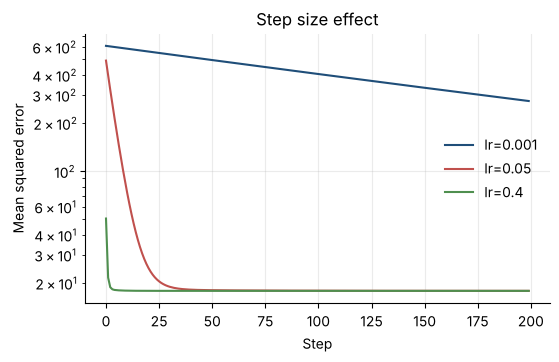

In [3]:
def descend(lr, steps=200):
    b, hist = np.zeros(3), []
    for _ in range(steps):
        b = b - lr * grad(b); hist.append(loss(b))
    return b, hist
exact = np.linalg.solve(X.T @ X, X.T @ y)
fig, ax = plt.subplots(figsize=(6, 3.5))
for lr in [0.001, 0.05, 0.4]:
    b, h = descend(lr); ax.plot(h, label=f"lr={lr}")
    print(f"lr={lr}: final loss {h[-1]:.3f}, distance to exact solution {np.linalg.norm(b - exact):.4f}")
ax.set_yscale("log"); ax.set_xlabel("Step"); ax.set_ylabel("Mean squared error"); ax.legend(); ax.set_title("Step size effect"); plt.show()

## 3. Scaling and conditioning

Without scaling the loss surface is a long narrow valley and gradient descent needs a tiny step size.

In [4]:
Xr = np.c_[np.ones(len(df)), df[["weight", "horsepower"]].values]
for name, M in [("scaled", X), ("raw", Xr)]:
    print(name, "condition number of X'X:", f"{np.linalg.cond(M.T @ M):.1f}")

scaled condition number of X'X: 13.8
raw condition number of X'X: 131658345.3


## 4. Beyond gradient descent: Newton step on a simple function

In [5]:
f = lambda x: (x - 3) ** 2 + np.sin(5 * x) * 0.2
x = 0.0
for i in range(10):
    h = 1e-4
    g = (f(x + h) - f(x - h)) / (2 * h); H = (f(x + h) - 2 * f(x) + f(x - h)) / h ** 2
    x = x - g / H
print("minimiser found by Newton steps:", round(float(x), 4), "| f:", round(float(f(x)), 4))

minimiser found by Newton steps: 2.5009 | f: 0.2367


## Exercises

1. Add momentum to `descend` and compare the loss after 50 steps.
2. Show with a plot that the raw features need a learning rate below 1e-7 to avoid divergence.

## Summary

- Gradients are checkable.
- Step size decides stability.
- Scaling improves conditioning.

**Next:** Machine learning concepts.

**Data note.** Real datasets come from `ml_lab.data` with licence notes in `datasets/catalog`. Synthetic numbers appear only where a demonstration needs controlled data, and are labelled.